# Solving the Wealth vs. Capital-Income Tax Equilibrium

**Companion notebook for Section 1.1, *Constant Elasticity Dynamic Programming***  
Saki Bigio, UCLA

This notebook solves the general equilibrium of the Epstein–Zin tax model on a grid over $(\tau, \tau^w)$ and computes the expected log-growth rate at each point. The setup matches the hand-derived equilibrium system from Section 1.1.

A household with preferences $(\beta, \theta, \gamma)$ holds wealth $W$ and chooses consumption $c$, safe capital $K^s$, and risky capital $K^r$. The government levies a capital-income tax $\tau$ and a wealth tax $\tau^w$. Prices $(p^c, p^s, p^r)$ are gradients of a CES production aggregator $\mathcal{H}(c+g,\, K^s,\, K^r)$; returns are $R^s = A^s/p^s$ and $R^r(s) = A^r(s)/p^r$.

We will (a) confirm the equilibrium structure, (b) explicitly handle the **timing of tax collection and spending** — a substantive modeling choice that materially affects results — (c) implement the GE fixed-point solver under two alternative timing conventions, (d) evaluate equilibrium on a $(\tau, \tau^w)$ grid for each convention, and (e) compare.

This is a Julia notebook. To run it you need Julia (1.10 or later) with `IJulia`, `NLsolve`, `Roots`, and `Plots` installed. The first cell below contains the package setup.


## (a) The Equilibrium System

The hand-derived equilibrium has two blocks:

**Income (production) block.** A CES aggregator $\mathcal{H}(\tilde c,\, K^s,\, K^r) = W$ with $\tilde c = c + g$. Linear homogeneity gives Euler's theorem: $p^c \tilde c + p^s K^s + p^r K^r = W$. Prices are gradients: $p^i = \partial \mathcal{H}/\partial x^i$, equivalent to the CES quantity-ratio relations on your page.

**Expenditure block.** Given after-tax returns

$$\bar R^s = 1 + (R^s - 1)(1-\tau), \qquad \bar R^r(s) = 1 + (R^r(s) - 1)(1-\tau),$$

the agent's problem yields:

- portfolio share $w^{r\ast}$ from $\mathbb{E}[(\bar R^p)^{-\gamma}(\bar R^r - \bar R^s)] = 0$,
- certainty equivalent $\bar{\mathcal R} = \mathrm{CE}_\gamma[(\bar R^r - \bar R^s) w^{r\ast} + \bar R^s]$,
- consumption-wealth ratio $x^\ast = 1 - \beta^\theta \big((1-\tau^w)\bar{\mathcal R}\big)^{\theta-1}$.

Demands after the wealth tax (which cuts the agent's resources to $(1-\tau^w)W$):

$$p^s K^s = (1-x^\ast)(1-w^{r\ast})(1-\tau^w)\, W, \quad p^r K^r = (1-x^\ast) w^{r\ast}(1-\tau^w)\, W, \quad p^c c = x^\ast(1-\tau^w)\, W.$$

**Notes on your derivation.** Three small points:

1. The portfolio formula written as $w^\ast = \tfrac{1}{1-\tau}\cdot \tfrac{\mathbb E[\bar R^r] - \bar R^s}{\gamma\,\mathrm{Var}[\bar R^r]}$ double-counts the Domar–Musgrave gross-up if taken literally — Merton applied to *after-tax* returns already gives $w^\ast(\tau) = w^\ast(0)/(1-\tau)$. Either compute Merton at no-tax returns and divide by $(1-\tau)$, or compute Merton at after-tax returns directly, but not both. The notebook does neither — it solves the FOC numerically, so the result is exact (no Merton approximation).

2. The government revenue line has $(1-\tau^w)$ cut off at the right edge of the page. The full expression: $T/W = \tau^w + \tau \cdot \mathbb{E}[r^p] \cdot (1-x^\ast)\,(1-\tau^w)$ — the income tax base is capital income from *after-wealth-tax* savings.

3. The growth-rate formula $g = \tfrac{\mathbb{E}[\bar R^p]}{\bar{\mathcal R}}(\beta \bar{\mathcal R})^\theta$ is the same as $\mathbb{E}[\log W_{t+1}/W_t] = \log(1-x^\ast) + \mathbb{E}[\log \bar R^p]$ in gross-factor form, for $\tau^w = 0$.


## The Timing of Taxes — A Substantive Modeling Choice

This is where the model has to make a commitment. The wealth tax is on the *stock* of $W$ at the start of period $t$. The capital-income tax is on the *flow* of capital income generated during period $t$ — income that materializes only at the *end* of the period, when capital matures into returns. So one cannot just lump the two revenues together as "current-period government spending" without saying when each is collected and when each is spent.

Three conventions:

### Convention A — Wealth-tax only in current-period market

The wealth tax $\tau^w$ is collected at start of $t$ and spent on consumption goods within period $t$. The income tax revenue is treated as a transfer or deferred — it does not enter the contemporaneous goods market. The within-period market-clearing identity sums to one:
$$x^\ast(1-\tau^w) + \tau^w + (1-x^\ast)(1-\tau^w) = 1.$$
The income tax still affects the agent's behavior through after-tax returns, but in this convention it is permanently sterilised. Convention A is the cleanest analytically.

### Convention B — Both taxes pre-collected on anticipated returns

The government collects the wealth tax AND the *expected* income tax revenue at the start of the period, and spends both within the period. Equivalently, the income tax is treated as deducted at-source from anticipated gross returns. Total revenue per $W$:
$$T/W = \tau^w + \tau \cdot \mathbb{E}[r^p_{\text{before}}](1-x^\ast)(1-\tau^w).$$
The within-period identity is reconciled by $\mathcal{H} = W \cdot (1 + \text{extra}_B)$, where $\text{extra}_B = \tau \mathbb{E}[r^p_{\text{before}}](1-x^\ast)(1-\tau^w)$ — economically, total period resources exceed the agent's wealth because the government holds a claim on anticipated income.

### Convention C — Lagged income tax (the economically realistic case)

Wealth tax collected and spent at start of $t$. Income tax collected at end of $t$ from realized returns and spent in period $t+1$. In the **stationary balanced-growth path**, the state of the economy in period $t$ is the agent's wealth $W_t$ *plus* the gov's accumulated tax liabilities from period $t-1$. Per-period gov spending is

$$\frac{G_t}{W_t} = \tau^w + \tau \cdot \mathbb{E}\!\left[\frac{r^p_{\text{before}}}{\bar R^p}\right],$$

where the second term comes from substituting the steady-state growth identity $W_{t-1}/W_t = 1/((1-x^\ast)(1-\tau^w)\bar R^p)$ — the $(1-x^\ast)(1-\tau^w)$ factors cancel, leaving only the return ratio. Then $\mathcal{H} = W (1 + \text{extra}_C)$ with
$$\text{extra}_C = \tau \cdot \mathbb{E}[r^p_{\text{before}}/\bar R^p].$$

**Convention C is the right one** — it matches real-world tax timing (income tax paid out of realized returns) and yet, under stationarity, requires no additional state variable beyond $W$. Conventions A and B bracket it: A understates current-period gov spending (treating income tax as eternally sterilised), and B overstates it (treating expected income tax as pre-claimed against current resources).

### Why this matters quantitatively

In general equilibrium the prices $(p^s, p^r)$ adjust to clear markets. Different conventions imply different total goods demand within the period, hence different equilibrium prices, returns, and growth rates. The growth-maximising tax pair and the partial-equilibrium-vs-GE wedge are both sensitive to the convention. We implement all three and compare.


## Setup

The notebook uses `NLsolve` (multi-variate root finding, like `scipy.optimize.fsolve`), `Roots` (one-dimensional, like `scipy.optimize.brentq`), and `Plots` for the contour and slice plots. Run the next cell once per fresh environment to install everything.


In [380]:
# Install packages (only need to run once per environment)
# Comment this cell out after first run if you want faster startup.
using Pkg
for pkg in ["NLsolve", "Roots", "Plots", "LaTeXStrings"]
    if !haskey(Pkg.project().dependencies, pkg)
        Pkg.add(pkg)
    end
end

using NLsolve
using Roots
using Plots
using LaTeXStrings
using Statistics
using Printf

gr()  # Plots backend
default(fontfamily="Computer Modern", titlefont=11, guidefont=10, tickfont=8, dpi=120)


## Parameters

Baseline matches Homework 3 Part IV: $\beta = 0.96$, $\theta = 1.5$, $\gamma = 5$. Safe return $r^s = 0.02$, risky returns $r^r \in \{-0.10,\, 0.20\}$ with equal probability. CES elasticity of substitution $\sigma = 0.5$ (gross complements between $\tilde c$, $K^s$, $K^r$ — this makes the GE feedback strong and visible).


In [381]:
# Preferences
const β = 0.99      # discount factor
const θ = 1.0       # IES
const γ = 10.95       # risk aversion

# Production (gross productivities; A_s set so R^s = 1.02 when p^s = 1)
const A_s = 1.04
const A_r = [0.99, 1.24]  # A_r for each state
const πst = [0.5, 0.5]   # state probabilities (π is reserved for the constant in Julia)

# CES aggregator
const σ_ces = 2.5

@printf("β = %.3f,  θ = %.2f,  γ = %.2f\n", β, θ, γ)
@printf("A_s = %.3f,  A_r = %s,  π = %s\n", A_s, A_r, πst)
@printf("σ_ces = %.2f\n", σ_ces)


β = 0.990,  θ = 1.00,  γ = 10.95
A_s = 1.040,  A_r = [0.99, 1.24],  π = [0.5, 0.5]
σ_ces = 2.50


## Helper Functions

CRRA certainty equivalent, exact portfolio FOC solver (no Merton approximation), the full agent problem, and the log-growth rate.


In [382]:
"""
    ce_crra(R_p, probs, γ)

CRRA certainty equivalent: CE = (Σ_s π_s · R_p[s]^(1-γ))^(1/(1-γ)).
Reduces to the geometric mean when γ → 1.
"""
function ce_crra(R_p::Vector{<:Real}, probs::Vector{<:Real}, γ::Real)
    if abs(γ - 1.0) < 1e-10
        return exp(sum(probs .* log.(R_p)))
    end
    return (sum(probs .* R_p .^ (1 - γ)))^(1 / (1 - γ))
end


"""
    solve_portfolio(R_s_bar, R_r_bar, probs, γ)

Solve the portfolio FOC E[(R^p)^(-γ)(R^r - R^s)] = 0 exactly (no Merton approximation).
Returns the risky share w*.
"""
function solve_portfolio(R_s_bar::Real, R_r_bar::Vector{<:Real},
                          probs::Vector{<:Real}, γ::Real)
    function foc(w)
        R_p = (1 - w) .* R_s_bar .+ w .* R_r_bar
        if any(R_p .<= 0)
            return w >= 0 ? 1e10 : -1e10
        end
        return sum(probs .* R_p .^ (-γ) .* (R_r_bar .- R_s_bar))
    end
    for (lo, hi) in [(-2.0, 2.0), (-5.0, 5.0), (-10.0, 10.0)]
        try
            f_lo = foc(lo); f_hi = foc(hi)
            if f_lo * f_hi < 0
                return find_zero(foc, (lo, hi), Bisection(); xatol=1e-10)
            end
        catch
            continue
        end
    end
    return NaN
end


"""
    agent_problem(R_s_bar, R_r_bar, probs, β, θ, γ, τ_w)

Solve the agent's full problem given after-tax returns and τ^w.
Returns (w*, R̄, x*, R^p_states).
"""
function agent_problem(R_s_bar::Real, R_r_bar::Vector{<:Real},
                       probs::Vector{<:Real}, β::Real, θ::Real, γ::Real, τ_w::Real)
    w_star = solve_portfolio(R_s_bar, R_r_bar, probs, γ)
    R_p_states = (1 - w_star) .* R_s_bar .+ w_star .* R_r_bar
    R_bar = ce_crra(R_p_states, probs, γ)
    x_star = 1 - β^θ * ((1 - τ_w) * R_bar)^(θ - 1)
    return (w=w_star, R_bar=R_bar, x=x_star, R_p=R_p_states)
end


"""
    log_growth(x, τ_w, R_p, probs)

Expected log growth: E[g(s)] = log(1-x*) + log(1-τ^w) + E[log R̄^p].
"""
function log_growth(x::Real, τ_w::Real, R_p::Vector{<:Real}, probs::Vector{<:Real})
    return log(1 - x) + log(1 - τ_w) + sum(probs .* log.(R_p))
end


log_growth

## No-Tax Baseline and CES Calibration

At the no-tax baseline both Conventions A and B agree (because `extra = 0` when $\tau = 0$). We choose equilibrium prices $p^c = p^s = p^r = 1$ as a normalization, then back out CES weights from the agent's demand shares:
$$s_i = \omega_i^\sigma \cdot p_i^{1-\sigma} \quad\Longrightarrow\quad \omega_i = s_i^{1/\sigma} \text{ at } p_i = 1.$$


In [383]:
# Solve at no-tax baseline (prices = 1, returns = productivities)
res0 = agent_problem(A_s, A_r, πst, β, θ, γ, 0.0)
w0, R̄0, x0, Rp0 = res0.w, res0.R_bar, res0.x, res0.R_p

println("No-tax baseline (prices p_c = p_s = p_r = 1):")
@printf("  w*     = %.4f\n", w0)
@printf("  R̄      = %.4f\n", R̄0)
@printf("  x*     = %.4f\n", x0)
@printf("  E[R^p] = %.4f\n", sum(πst .* Rp0))
@printf("  E[g]   = %.4f (%.3f%%)\n", log_growth(x0, 0.0, Rp0, πst),
        100*log_growth(x0, 0.0, Rp0, πst))

# Calibrate CES weights so that demand shares match at p_i = 1
const ω_c = x0^(1/σ_ces)
const ω_s = ((1 - x0) * (1 - w0))^(1/σ_ces)
const ω_r = ((1 - x0) * w0)^(1/σ_ces)

println("\nCalibrated CES weights (σ = $σ_ces):")
@printf("  ω_c = %.4f\n", ω_c)
@printf("  ω_s = %.4f\n", ω_s)
@printf("  ω_r = %.4f\n", ω_r)
@printf("  Sum of CES shares = %.4f   (should be 1.0)\n",
        ω_c^σ_ces + ω_s^σ_ces + ω_r^σ_ces)


No-tax baseline (prices p_c = p_s = p_r = 1):
  w*     = 0.5467
  R̄      = 1.0588
  x*     = 0.0100
  E[R^p] = 1.0810
  E[g]   = 0.0658 (6.584%)

Calibrated CES weights (σ = 2.5):
  ω_c = 0.1585
  ω_s = 0.7258
  ω_r = 0.7823
  Sum of CES shares = 1.0000   (should be 1.0)


## General Equilibrium Solver (with convention as a parameter)

For each $(\tau, \tau^w)$, find $(p_s, p_r)$ with $p_c = 1$ that satisfies both the agent's optimization AND the market-clearing conditions corresponding to the chosen convention.

In all three conventions the market-clearing equations have the same form:
$$\omega_s^\sigma p_s^{1-\sigma}\,(1+\text{extra}) = (1-x^\ast)(1-w^\ast)(1-\tau^w), \quad \omega_r^\sigma p_r^{1-\sigma}\,(1+\text{extra}) = (1-x^\ast)w^\ast(1-\tau^w).$$
Only the `extra` term differs:

| Convention | `extra` formula |
|---|---|
| A | $0$ |
| B | $\tau \cdot \mathbb{E}[r^p_{\text{before}}](1-x^\ast)(1-\tau^w)$ |
| C | $\tau \cdot \mathbb{E}[r^p_{\text{before}}/\bar R^p]$ |

So implementation differs by exactly one line. The agent's optimization is identical across conventions; only $\mathcal{H}$ scales differently.


In [384]:
"""
    solve_ge(τ, τ_w; convention=:C, ...)

Solve the general equilibrium for taxes (τ, τ_w) under one of three timing conventions.

- :A — wealth tax only in current-period market (income tax deferred indefinitely)
- :B — both taxes pre-collected on expected returns
- :C — lagged income tax; stationary expectation H = W(1 + extra_C)  ← canonical

The agent's optimization is identical across conventions. Only the within-period
market-clearing condition (the CES "extra") differs.
"""
function solve_ge(τ::Real, τ_w::Real;
                  convention::Symbol = :C,
                  ω_c::Real = ω_c, ω_s::Real = ω_s, ω_r::Real = ω_r,
                  σ::Real = σ_ces, x0 = [1.0, 1.0])

    function residual!(F, p)
        p_s, p_r = p[1], p[2]
        if p_s <= 1e-6 || p_r <= 1e-6
            F .= [1e10, 1e10]; return nothing
        end
        R_s = A_s / p_s
        R_r = A_r ./ p_r
        R_s_bar = 1 + (R_s - 1) * (1 - τ)
        R_r_bar = 1 .+ (R_r .- 1) .* (1 - τ)
        res = agent_problem(R_s_bar, R_r_bar, πst, β, θ, γ, τ_w)
        w_, x_, R_p_after_ = res.w, res.x, res.R_p
        if isnan(w_) || isnan(x_) || x_ >= 1.0
            F .= [1e10, 1e10]; return nothing
        end
        s_s_demand = (1 - x_) * (1 - w_) * (1 - τ_w)
        s_r_demand = (1 - x_) *      w_  * (1 - τ_w)
        R_p_before = (1 - w_) .* R_s .+ w_ .* R_r
        if convention == :A
            extra = 0.0
        elseif convention == :B
            E_rp_before = sum(πst .* (R_p_before .- 1))
            extra = τ * E_rp_before * (1 - x_) * (1 - τ_w)
        elseif convention == :C
            # Stationary expectation: τ · E[r^p_before / R̄^p_after]
            E_ratio = sum(πst .* (R_p_before .- 1) ./ R_p_after_)
            extra = τ * E_ratio
        else
            error("Unknown convention: $convention")
        end
        scale = 1.0 + extra
        s_s_ces = ω_s^σ * p_s^(1 - σ) * scale
        s_r_ces = ω_r^σ * p_r^(1 - σ) * scale
        F[1] = s_s_demand - s_s_ces
        F[2] = s_r_demand - s_r_ces
        return nothing
    end

    sol = nlsolve(residual!, x0; ftol=1e-9, iterations=200)
    if !converged(sol)
        return nothing
    end
    p_s_eq, p_r_eq = sol.zero
    if p_s_eq <= 0 || p_r_eq <= 0
        return nothing
    end

    R_s = A_s / p_s_eq
    R_r = A_r ./ p_r_eq
    R_s_bar = 1 + (R_s - 1) * (1 - τ)
    R_r_bar = 1 .+ (R_r .- 1) .* (1 - τ)
    res = agent_problem(R_s_bar, R_r_bar, πst, β, θ, γ, τ_w)
    g = log_growth(res.x, τ_w, res.R_p, πst)

    R_p_before = (1 - res.w) .* R_s .+ res.w .* R_r
    E_rp_before = sum(πst .* (R_p_before .- 1))
    E_ratio     = sum(πst .* (R_p_before .- 1) ./ res.R_p)

    T_per_W = if convention == :A
        τ_w
    elseif convention == :B
        τ_w + τ * E_rp_before * (1 - res.x) * (1 - τ_w)
    else
        τ_w + τ * E_ratio
    end

    return (p_s=p_s_eq, p_r=p_r_eq, R_s=R_s, R_r=R_r,
            R_s_bar=R_s_bar, R_r_bar=R_r_bar,
            w=res.w, R_bar=res.R_bar, x=res.x, R_p=res.R_p,
            g=g, T_per_W=T_per_W, convention=convention)
end


solve_ge

In [385]:
# Sanity check: at τ=τ_w=0, all three conventions should give the no-tax baseline
for conv in [:A, :B, :C]
    r = solve_ge(0.0, 0.0, convention=conv)
    @printf("  %s: p_s=%.4f  p_r=%.4f  w*=%.4f  x*=%.4f  g=%.4f\n",
            conv, r.p_s, r.p_r, r.w, r.x, r.g)
end

println("\nA few scenarios with taxes (Convention C is the canonical/realistic case):")
for (τ, τ_w) in [(0.0, 0.02), (0.20, 0.0), (0.20, 0.02), (0.40, 0.05)]
    println("\n  τ=$τ, τ_w=$τ_w:")
    for conv in [:A, :B, :C]
        r = solve_ge(τ, τ_w, convention=conv)
        if r !== nothing
            @printf("    %s: p_s=%.4f  R_s=%.4f  w*=%.4f  x*=%.4f  g=%+.4f  T/W=%.4f\n",
                    conv, r.p_s, r.R_s, r.w, r.x, r.g, r.T_per_W)
        end
    end
end


  A: p_s=1.0000  p_r=1.0000  w*=0.5467  x*=0.0100  g=0.0658
  B: p_s=1.0000  p_r=1.0000  w*=0.5467  x*=0.0100  g=0.0658
  C: p_s=1.0000  p_r=1.0000  w*=0.5467  x*=0.0100  g=0.0658

A few scenarios with taxes (Convention C is the canonical/realistic case):

  τ=0.0, τ_w=0.02:
    A: p_s=1.0136  R_s=1.0261  w*=0.5467  x*=0.0100  g=+0.0322  T/W=0.0200
    B: p_s=1.0136  R_s=1.0261  w*=0.5467  x*=0.0100  g=+0.0322  T/W=0.0200
    C: p_s=1.0136  R_s=1.0261  w*=0.5467  x*=0.0100  g=+0.0322  T/W=0.0200

  τ=0.2, τ_w=0.0:
    A: p_s=0.9938  R_s=1.0465  w*=0.5425  x*=0.0100  g=+0.0511  T/W=0.0000
    B: p_s=1.0030  R_s=1.0369  w*=0.5424  x*=0.0100  g=+0.0436  T/W=0.0140
    C: p_s=1.0023  R_s=1.0376  w*=0.5424  x*=0.0100  g=+0.0442  T/W=0.0129

  τ=0.2, τ_w=0.02:
    A: p_s=1.0072  R_s=1.0325  w*=0.5424  x*=0.0100  g=+0.0200  T/W=0.0200
    B: p_s=1.0147  R_s=1.0249  w*=0.5424  x*=0.0100  g=+0.0139  T/W=0.0313
    C: p_s=1.0143  R_s=1.0254  w*=0.5424  x*=0.0100  g=+0.0143  T/W=0.0306

  τ=0.4, 

## Grid over $(\tau, \tau^w)$ — Both Conventions

Sweep $\tau \in [0, 0.40]$ and $\tau^w \in [0, 0.05]$ on a $21 \times 21$ grid, solving the GE under each convention at each point.


In [386]:
const τ_grid   = collect(range(-0.4, 0.4, length=101))
const τ_w_grid = collect(range(-0.25, 0.25, length=101))
const Nτ, Nτw = length(τ_grid), length(τ_w_grid)

init_grid() = fill(NaN, Nτ, Nτw)

# Storage for each convention
grids = Dict{Symbol, Dict{Symbol, Matrix{Float64}}}()
for conv in [:A, :B, :C]
    grids[conv] = Dict(:g => init_grid(), :x => init_grid(), :w => init_grid(),
                       :p_s => init_grid(), :p_r => init_grid(), :T => init_grid())
end

for (i, τ) in enumerate(τ_grid), (j, τ_w) in enumerate(τ_w_grid)
    for conv in [:A, :B, :C]
        r = solve_ge(τ, τ_w, convention=conv)
        if r !== nothing
            grids[conv][:g][i,j]   = r.g
            grids[conv][:x][i,j]   = r.x
            grids[conv][:w][i,j]   = r.w
            grids[conv][:p_s][i,j] = r.p_s
            grids[conv][:p_r][i,j] = r.p_r
            grids[conv][:T][i,j]   = r.T_per_W
        end
    end
end

println("Grid solved.")
for conv in [:A, :B, :C]
    G = grids[conv][:g]
    nfail = count(isnan, G)
    valid = filter(!isnan, G)
    @printf("  Convention %s: min g = %.3f%%, max g = %.3f%%, failures = %d/%d\n",
            conv, 100*minimum(valid), 100*maximum(valid), nfail, length(G))
end


Grid solved.
  Convention A: min g = -46.404%, max g = 51.518%, failures = 0/10201
  Convention B: min g = -50.110%, max g = 78.433%, failures = 0/10201
  Convention C: min g = -54.095%, max g = 59.617%, failures = 0/10201


In [387]:
# ── Check: do expenditure shares sum to 1 at every grid point? ────────────────
#
# Agent demands (fractions of W):
#   consumption = x,  safe = (1-x)(1-w)(1-τ_w),  risky = (1-x)w(1-τ_w),  tax = (1-x)τ_w
# Grand total should be 1.
#
# CES supply side: s_ces = ω_s^σ p_s^{1-σ} · scale,  etc.
# Solver clears safe & risky markets. Walras ⟹ consumption should clear too:
#   x = ω_c^σ · scale    (residual should be ≈ 0)

println("Expenditure-share diagnostics")
println("=" ^ 70)

for conv in [:A, :C, :B]
    x_mat  = grids[conv][:x]
    w_mat  = grids[conv][:w]
    ps_mat = grids[conv][:p_s]
    pr_mat = grids[conv][:p_r]

    agent_sum  = fill(NaN, Nτ, Nτw)
    walras_err = fill(NaN, Nτ, Nτw)
    ces_total  = fill(NaN, Nτ, Nτw)

    for (i, τ) in enumerate(τ_grid), (j, τ_w) in enumerate(τ_w_grid)
        x_  = x_mat[i,j];   w_ = w_mat[i,j]
        ps_ = ps_mat[i,j];  pr_ = pr_mat[i,j]
        (isnan(x_) || isnan(ps_)) && continue

        # Agent side (including tax → should be 1)
        c_  = x_
        s_  = (1 - x_) * (1 - w_) * (1 - τ_w)
        r_  = (1 - x_) *      w_  * (1 - τ_w)
        tw_ = (1 - x_) * τ_w
        agent_sum[i,j] = c_ + s_ + r_ + tw_

        # Recover scale from safe-market clearing
        ces_s = ω_s^σ_ces * ps_^(1 - σ_ces)
        (ces_s ≈ 0) && continue
        scale_ = s_ / ces_s

        # CES total
        ces_total[i,j] = scale_ * (ω_c^σ_ces + ω_s^σ_ces * ps_^(1 - σ_ces) + ω_r^σ_ces * pr_^(1 - σ_ces))

        # Walras residual: does x = ω_c^σ · scale?
        walras_err[i,j] = x_ - ω_c^σ_ces * scale_
    end

    valid_a = filter(!isnan, vec(agent_sum))
    valid_w = filter(!isnan, vec(walras_err))
    valid_c = filter(!isnan, vec(ces_total))

    @printf("\nConvention %s  (%d valid points):\n", conv, length(valid_a))
    @printf("  Agent c+s+r+tax:   min = %.6f,  max = %.6f  (should be 1)\n",
            minimum(valid_a), maximum(valid_a))
    @printf("  CES total:         min = %.6f,  max = %.6f\n",
            minimum(valid_c), maximum(valid_c))
    @printf("  Walras residual:   min = %+.2e, max = %+.2e  (should be ≈0)\n",
            minimum(valid_w), maximum(valid_w))
end


Expenditure-share diagnostics

Convention A  (10201 valid points):
  Agent c+s+r+tax:   min = 1.000000,  max = 1.000000  (should be 1)
  CES total:         min = 0.752500,  max = 1.247500
  Walras residual:   min = -1.34e-12, max = +2.46e-11  (should be ≈0)

Convention C  (10201 valid points):
  Agent c+s+r+tax:   min = 1.000000,  max = 1.000000  (should be 1)
  CES total:         min = 0.752129,  max = 1.248199
  Walras residual:   min = -8.04e-04, max = +9.03e-04  (should be ≈0)

Convention B  (10201 valid points):
  Agent c+s+r+tax:   min = 1.000000,  max = 1.000000  (should be 1)
  CES total:         min = 0.752227,  max = 1.248406
  Walras residual:   min = -9.06e-04, max = +2.74e-03  (should be ≈0)


## Expected Growth Across the Tax Grid — Three Conventions Side by Side

Top row: $\mathbb{E}[g(s)]$ under each convention on a shared color scale. Bottom row: differences (B − C and A − C) relative to the canonical Convention C.


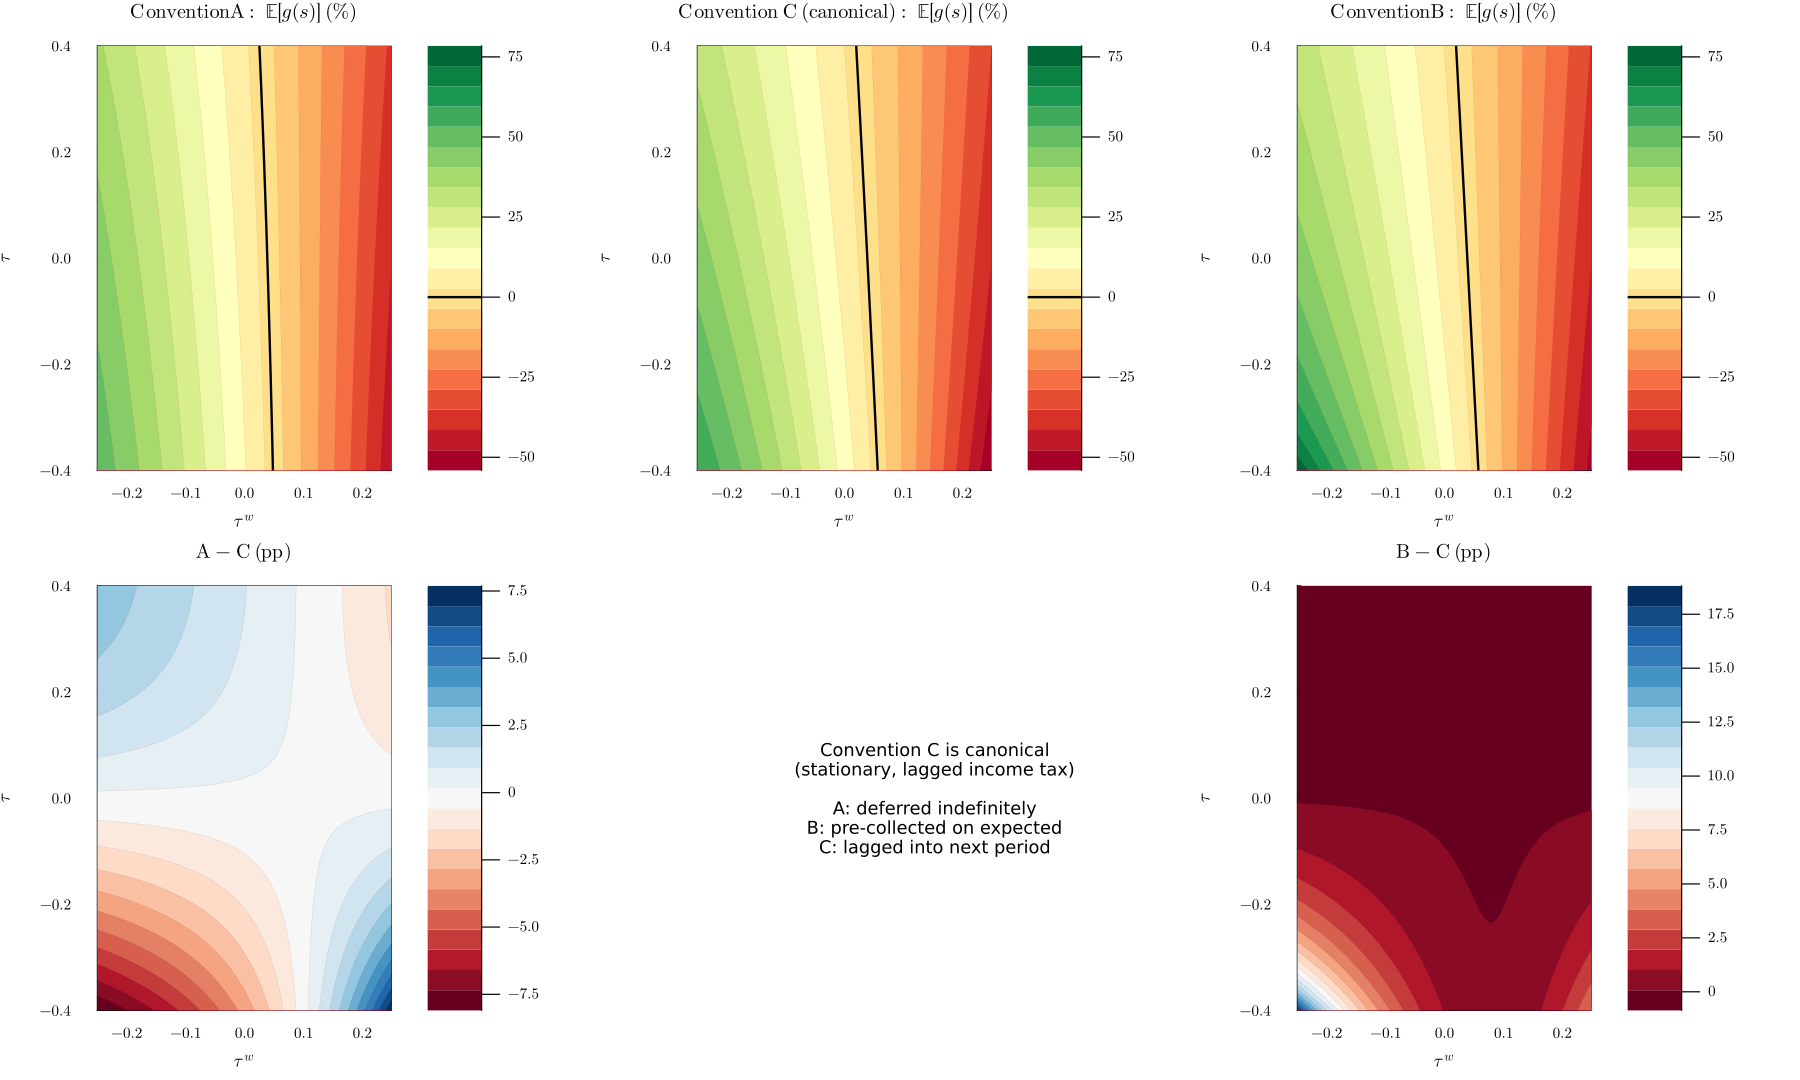

In [388]:
G_A_pct = 100 .* grids[:A][:g]
G_B_pct = 100 .* grids[:B][:g]
G_C_pct = 100 .* grids[:C][:g]

gmin = min(minimum(filter(!isnan, G_A_pct)),
           minimum(filter(!isnan, G_B_pct)),
           minimum(filter(!isnan, G_C_pct)))
gmax = max(maximum(filter(!isnan, G_A_pct)),
           maximum(filter(!isnan, G_B_pct)),
           maximum(filter(!isnan, G_C_pct)))

# Top row: three conventions on a shared color scale
p1 = contourf(τ_w_grid, τ_grid, G_A_pct;
              xlabel=L"\tau^w", ylabel=L"\tau",
              title=L"\textrm{Convention A:}\ \mathbb{E}[g(s)]\ (\%)",
              clims=(gmin, gmax), c=:RdYlGn, levels=20, linewidth=0)
contour!(p1, τ_w_grid, τ_grid, G_A_pct; levels=[0], c=:black, linewidth=2, label="")

p2 = contourf(τ_w_grid, τ_grid, G_C_pct;
              xlabel=L"\tau^w", ylabel=L"\tau",
              title=L"\textrm{Convention\ C\ (canonical):}\ \mathbb{E}[g(s)]\ (\%)",
              clims=(gmin, gmax), c=:RdYlGn, levels=20, linewidth=0)
contour!(p2, τ_w_grid, τ_grid, G_C_pct; levels=[0], c=:black, linewidth=2, label="")

p3 = contourf(τ_w_grid, τ_grid, G_B_pct;
              xlabel=L"\tau^w", ylabel=L"\tau",
              title=L"\textrm{Convention B:}\ \mathbb{E}[g(s)]\ (\%)",
              clims=(gmin, gmax), c=:RdYlGn, levels=20, linewidth=0)
contour!(p3, τ_w_grid, τ_grid, G_B_pct; levels=[0], c=:black, linewidth=2, label="")

# Bottom row: differences relative to C (the canonical case)
p4 = contourf(τ_w_grid, τ_grid, G_A_pct .- G_C_pct;
              xlabel=L"\tau^w", ylabel=L"\tau",
              title=L"\textrm{A}-\textrm{C\ (pp)}",
              c=:RdBu, levels=20, linewidth=0)

# Middle bottom: explanatory text via empty plot
p5 = plot(framestyle=:none, ticks=nothing, legend=false)
annotate!(p5, 0.5, 0.5, text(
    "Convention C is canonical\n" *
    "(stationary, lagged income tax)\n\n" *
    "A: deferred indefinitely\n" *
    "B: pre-collected on expected\n" *
    "C: lagged into next period",
    10, :center))

p6 = contourf(τ_w_grid, τ_grid, G_B_pct .- G_C_pct;
              xlabel=L"\tau^w", ylabel=L"\tau",
              title=L"\textrm{B}-\textrm{C\ (pp)}",
              c=:RdBu, levels=20, linewidth=0)

plot(p1, p2, p3, p4, p5, p6; layout=(2,3), size=(1500, 900), margin=4Plots.mm)


## Slice Plots: One Tax at a Time, Both Conventions

For each convention, slice the grid at fixed $\tau^w$ and vary $\tau$ (left), and at fixed $\tau$ varying $\tau^w$ (right). This lets us read off the partial effect of each tax cleanly, and see how the convention shifts the level.


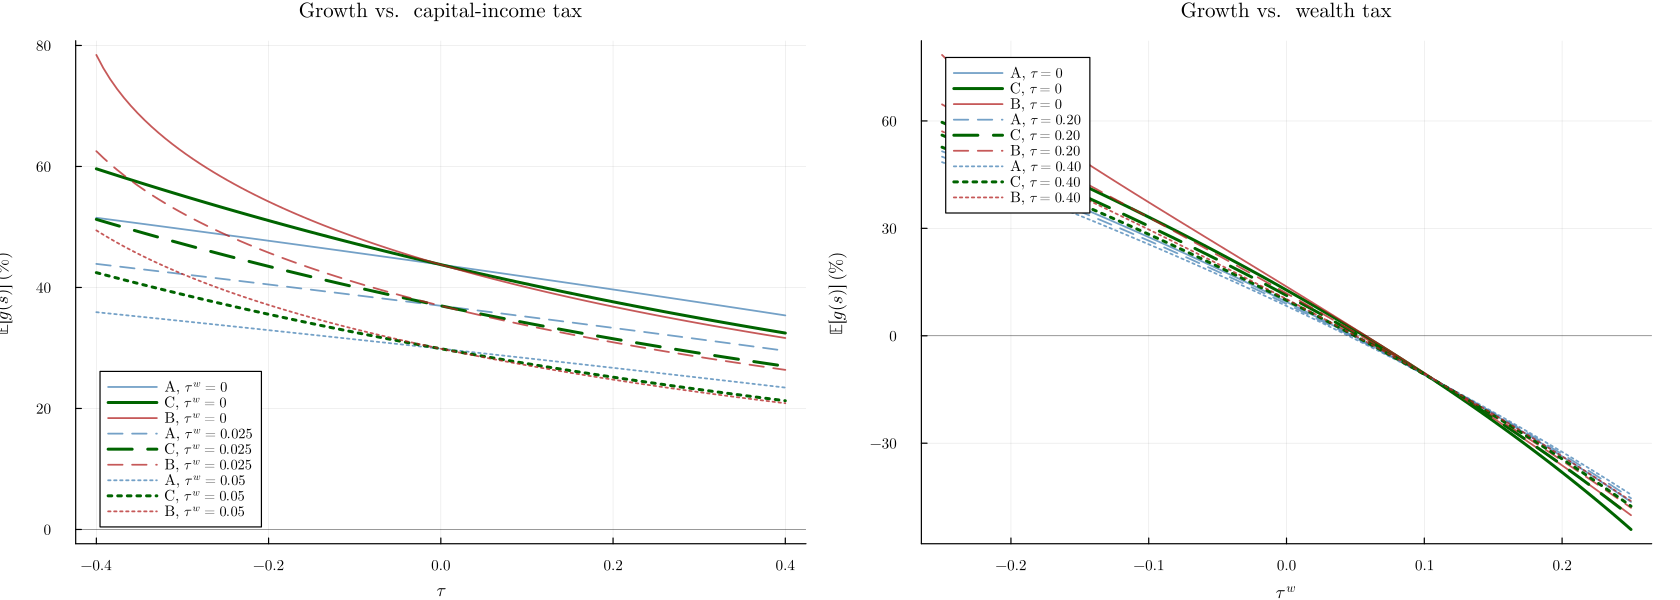

In [389]:
G_A_pct = 100 .* grids[:A][:g]
G_B_pct = 100 .* grids[:B][:g]
G_C_pct = 100 .* grids[:C][:g]

# Left: g vs τ at three values of τ_w
plot_left = plot(xlabel=L"\tau", ylabel=L"\mathbb{E}[g(s)]\ (\%)",
                 title="Growth vs.  capital-income tax",
                 grid=true, legend=:bottomleft)
for (j, ls, label_w) in [(1,  :solid,  L"\tau^w=0"),
                          (11, :dash,   L"\tau^w=0.025"),
                          (21, :dot,    L"\tau^w=0.05")]
    plot!(plot_left, τ_grid, G_A_pct[:, j]; label="A, $label_w", color=:steelblue, linestyle=ls, linewidth=1.5, alpha=0.75)
    plot!(plot_left, τ_grid, G_C_pct[:, j]; label="C, $label_w", color=:darkgreen, linestyle=ls, linewidth=2.5)
    plot!(plot_left, τ_grid, G_B_pct[:, j]; label="B, $label_w", color=:firebrick, linestyle=ls, linewidth=1.5, alpha=0.75)
end
hline!(plot_left, [0]; color=:black, linewidth=0.5, alpha=0.6, label="")

# Right: g vs τ_w at three values of τ
plot_right = plot(xlabel=L"\tau^w", ylabel=L"\mathbb{E}[g(s)]\ (\%)",
                  title="Growth vs.  wealth tax",
                  grid=true, legend=:topleft)
for (i, ls, label_t) in [(1,  :solid, L"\tau=0"),
                          (11, :dash,  L"\tau=0.20"),
                          (21, :dot,   L"\tau=0.40")]
    plot!(plot_right, τ_w_grid, G_A_pct[i, :]; label="A, $label_t", color=:steelblue, linestyle=ls, linewidth=1.5, alpha=0.75)
    plot!(plot_right, τ_w_grid, G_C_pct[i, :]; label="C, $label_t", color=:darkgreen, linestyle=ls, linewidth=2.5)
    plot!(plot_right, τ_w_grid, G_B_pct[i, :]; label="B, $label_t", color=:firebrick, linestyle=ls, linewidth=1.5, alpha=0.75)
end
hline!(plot_right, [0]; color=:black, linewidth=0.5, alpha=0.6, label="")

plot(plot_left, plot_right; layout=(1,2), size=(1400, 500), margin=4Plots.mm)


## Government Revenue Under Each Convention

A useful sanity check: what does the government actually collect per unit of wealth under each convention? Convention A only counts the wealth tax; Convention B counts both.


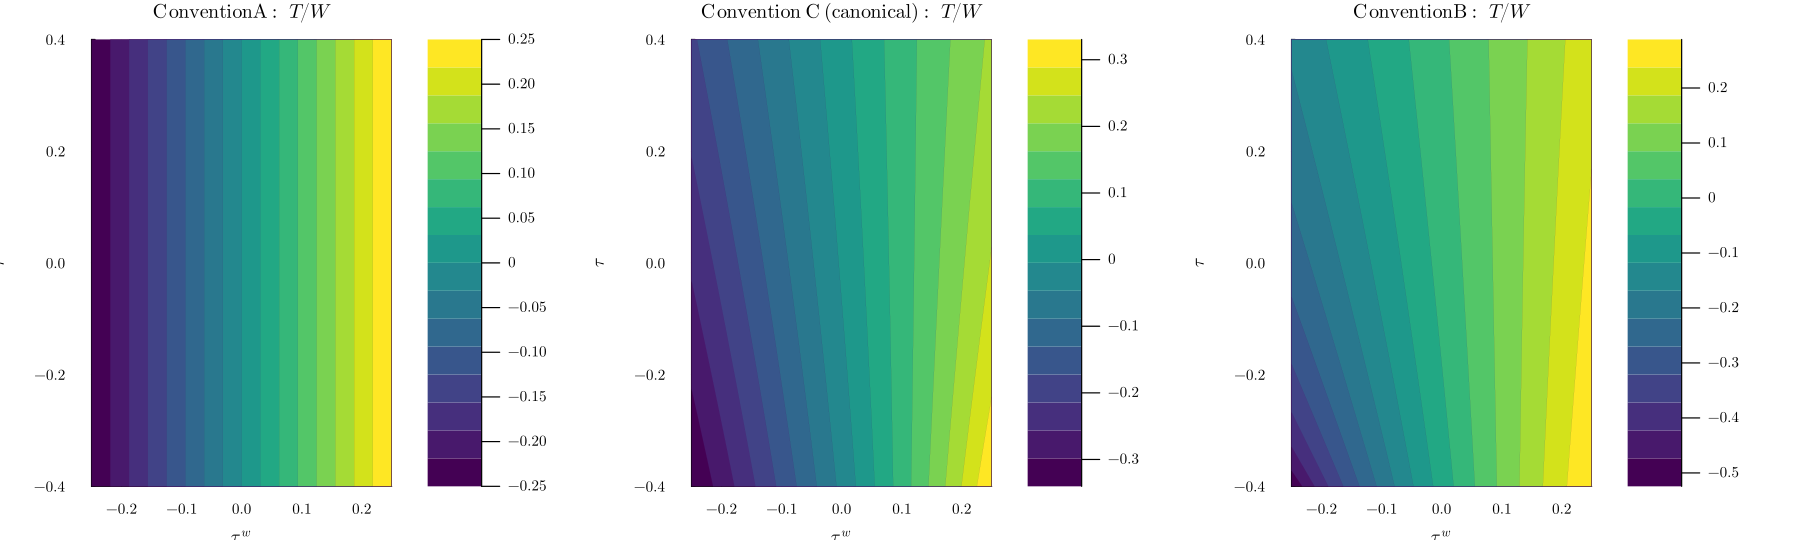

In [390]:
p1 = contourf(τ_w_grid, τ_grid, grids[:A][:T];
              xlabel=L"\tau^w", ylabel=L"\tau",
              title=L"\textrm{Convention A:}\ T/W",
              c=:viridis, levels=15, linewidth=0)
p2 = contourf(τ_w_grid, τ_grid, grids[:C][:T];
              xlabel=L"\tau^w", ylabel=L"\tau",
              title=L"\textrm{Convention\ C\ (canonical):}\ T/W",
              c=:viridis, levels=15, linewidth=0)
p3 = contourf(τ_w_grid, τ_grid, grids[:B][:T];
              xlabel=L"\tau^w", ylabel=L"\tau",
              title=L"\textrm{Convention B:}\ T/W",
              c=:viridis, levels=15, linewidth=0)
plot(p1, p2, p3; layout=(1,3), size=(1500, 450), margin=4Plots.mm)


## Growth-Maximising Tax Pair Under Each Convention

Different conventions may yield different growth-maximising tax pairs. We argmax over the grid under each.


In [391]:
function argmax_grid(G)
    idx = argmax(replace(G, NaN => -Inf))
    return idx[1], idx[2], G[idx]
end

println("Growth-maximising tax pair on the grid:")
println("-" ^ 70)
for conv in [:A, :C, :B]
    G = grids[conv][:g]
    i, j, gmax = argmax_grid(G)
    label = conv == :C ? " (canonical)" : ""
    @printf("  Convention %s%s:  τ* = %.3f, τ_w* = %.3f, E[g] = %+.4f (%.3f%%)\n",
            conv, label, τ_grid[i], τ_w_grid[j], gmax, 100*gmax)
end
@printf("  No-tax baseline:                              E[g] = %+.4f (%.3f%%)\n",
        grids[:A][:g][1,1], 100*grids[:A][:g][1,1])

println()
println("Where C sits between A and B:")
diff_CA = grids[:C][:g] .- grids[:A][:g]
diff_BC = grids[:B][:g] .- grids[:C][:g]
@printf("  C - A: ranges from %+.3f to %+.3f pp\n",
        100*minimum(filter(!isnan, diff_CA)), 100*maximum(filter(!isnan, diff_CA)))
@printf("  B - C: ranges from %+.3f to %+.3f pp\n",
        100*minimum(filter(!isnan, diff_BC)), 100*maximum(filter(!isnan, diff_BC)))
println()
println("Convention C is the realistic choice (lagged income tax + stationarity).")
println("It bounds A from above (gov spends more than nothing) and B from below")
println("(gov doesn't get to spend the entire anticipated revenue stream now).")


Growth-maximising tax pair on the grid:
----------------------------------------------------------------------
  Convention A:  τ* = -0.400, τ_w* = -0.250, E[g] = +0.5152 (51.518%)
  Convention C (canonical):  τ* = -0.400, τ_w* = -0.250, E[g] = +0.5962 (59.617%)
  Convention B:  τ* = -0.400, τ_w* = -0.250, E[g] = +0.7843 (78.433%)
  No-tax baseline:                              E[g] = +0.5152 (51.518%)

Where C sits between A and B:
  C - A: ranges from -7.690 to +8.099 pp
  B - C: ranges from -0.861 to +18.815 pp

Convention C is the realistic choice (lagged income tax + stationarity).
It bounds A from above (gov spends more than nothing) and B from below
(gov doesn't get to spend the entire anticipated revenue stream now).


## Present Discounted Value of Government Revenue

The per-period government take is $T/W$.  Since wealth grows at gross rate
$G = e^{g}$, the present discounted value of the entire revenue stream
(per unit of current wealth) is

$$
  PDV = \frac{T/W}{1 - \beta\, G}
$$

which is well-defined whenever $\beta G < 1$.

β_gov = 0.95,  color range = [0.6371, 1.9818]


┌ Warning: Multiple series with different color share a colorbar.
│ Colorbar may not reflect all series correctly.
└ @ Plots ~/.julia/packages/Plots/GIume/src/backends/gr.jl:530
┌ Warning: Multiple series with different line style share a colorbar.
│ Colorbar may not reflect all series correctly.
└ @ Plots ~/.julia/packages/Plots/GIume/src/backends/gr.jl:530
┌ Warning: Multiple series with different line color share a colorbar.
│ Colorbar may not reflect all series correctly.
└ @ Plots ~/.julia/packages/Plots/GIume/src/backends/gr.jl:530
┌ Warning: Multiple series with different levels share a colorbar.
│ Colorbar may not reflect all series correctly.
└ @ Plots ~/.julia/packages/Plots/GIume/src/backends/gr.jl:530
┌ Warning: Multiple series with different color share a colorbar.
│ Colorbar may not reflect all series correctly.
└ @ Plots ~/.julia/packages/Plots/GIume/src/backends/gr.jl:530
┌ Warning: Multiple series with different line style share a colorbar.
│ Colorbar may not reflect a

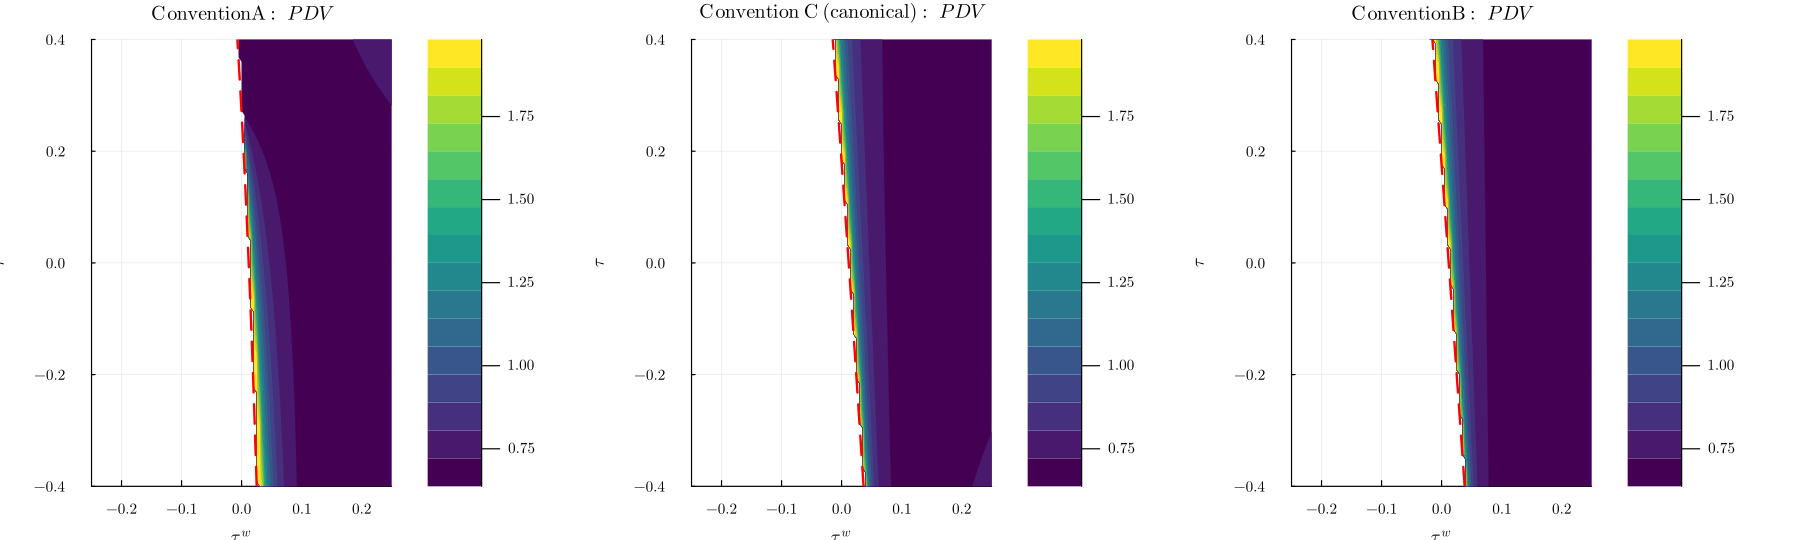

┌ Warning: Multiple series with different line color share a colorbar.
│ Colorbar may not reflect all series correctly.
└ @ Plots ~/.julia/packages/Plots/GIume/src/backends/gr.jl:530
┌ Warning: Multiple series with different levels share a colorbar.
│ Colorbar may not reflect all series correctly.
└ @ Plots ~/.julia/packages/Plots/GIume/src/backends/gr.jl:530
┌ Warning: Multiple series with different color share a colorbar.
│ Colorbar may not reflect all series correctly.
└ @ Plots ~/.julia/packages/Plots/GIume/src/backends/gr.jl:530
┌ Warning: Multiple series with different line style share a colorbar.
│ Colorbar may not reflect all series correctly.
└ @ Plots ~/.julia/packages/Plots/GIume/src/backends/gr.jl:530
┌ Warning: Multiple series with different line color share a colorbar.
│ Colorbar may not reflect all series correctly.
└ @ Plots ~/.julia/packages/Plots/GIume/src/backends/gr.jl:530
┌ Warning: Multiple series with different levels share a colorbar.
│ Colorbar may not reflect 

In [392]:
# PDV of government revenue: (T/W) / (1 - β_gov * exp(g))
# Using a lower discount factor to keep denominator well away from zero
β_gov = β - 0.035

PDV = Dict{Symbol, Matrix{Float64}}()
BG  = Dict{Symbol, Matrix{Float64}}()
for conv in [:A, :B, :C]
    g_mat   = grids[conv][:g]
    G_gross = exp.(g_mat)
    bg      = β_gov .* G_gross
    denom   = 1 .- bg
    pdv     = grids[conv][:T] ./ denom
    pdv[denom .<= 0]    .= NaN
    pdv[isnan.(g_mat)]  .= NaN
    PDV[conv] = pdv
    BG[conv]  = bg
end

# Color scale from 2nd–98th percentile
all_vals = sort(filter(!isnan, vcat(vec(PDV[:A]), vec(PDV[:B]), vec(PDV[:C]))))
pdv_lo = all_vals[max(1, round(Int, 0.02*length(all_vals)))]
pdv_hi = all_vals[min(length(all_vals), round(Int, 0.98*length(all_vals)))]

p1 = contourf(τ_w_grid, τ_grid, clamp.(PDV[:A], pdv_lo, pdv_hi);
              xlabel=L"\tau^w", ylabel=L"\tau",
              title=L"\textrm{Convention A:}\ PDV",
              clims=(pdv_lo, pdv_hi), c=:viridis, levels=15, linewidth=0)
contour!(p1, τ_w_grid, τ_grid, BG[:A]; levels=[1.0], c=:red, linewidth=2, ls=:dash, label=L"\beta_{gov} G = 1")
contour!(p1, τ_w_grid, τ_grid, grids[:A][:g]; levels=[0.0], c=:white, linewidth=2, label=L"g = 0")

p2 = contourf(τ_w_grid, τ_grid, clamp.(PDV[:C], pdv_lo, pdv_hi);
              xlabel=L"\tau^w", ylabel=L"\tau",
              title=L"\textrm{Convention\ C\ (canonical):}\ PDV",
              clims=(pdv_lo, pdv_hi), c=:viridis, levels=15, linewidth=0)
contour!(p2, τ_w_grid, τ_grid, BG[:C]; levels=[1.0], c=:red, linewidth=2, ls=:dash, label=L"\beta_{gov} G = 1")
contour!(p2, τ_w_grid, τ_grid, grids[:C][:g]; levels=[0.0], c=:white, linewidth=2, label=L"g = 0")

p3 = contourf(τ_w_grid, τ_grid, clamp.(PDV[:B], pdv_lo, pdv_hi);
              xlabel=L"\tau^w", ylabel=L"\tau",
              title=L"\textrm{Convention B:}\ PDV",
              clims=(pdv_lo, pdv_hi), c=:viridis, levels=15, linewidth=0)
contour!(p3, τ_w_grid, τ_grid, BG[:B]; levels=[1.0], c=:red, linewidth=2, ls=:dash, label=L"\beta_{gov} G = 1")
contour!(p3, τ_w_grid, τ_grid, grids[:B][:g]; levels=[0.0], c=:white, linewidth=2, label=L"g = 0")

@printf("β_gov = %.2f,  color range = [%.4f, %.4f]\n", β_gov, pdv_lo, pdv_hi)
plot(p1, p2, p3; layout=(1,3), size=(1500, 450), margin=4Plots.mm)

### PDV Slice Plots and Interior Maximum

Slice plots hold one tax fixed and vary the other, showing PDV profiles
for all three conventions. The interior maximum (if any) is reported below.

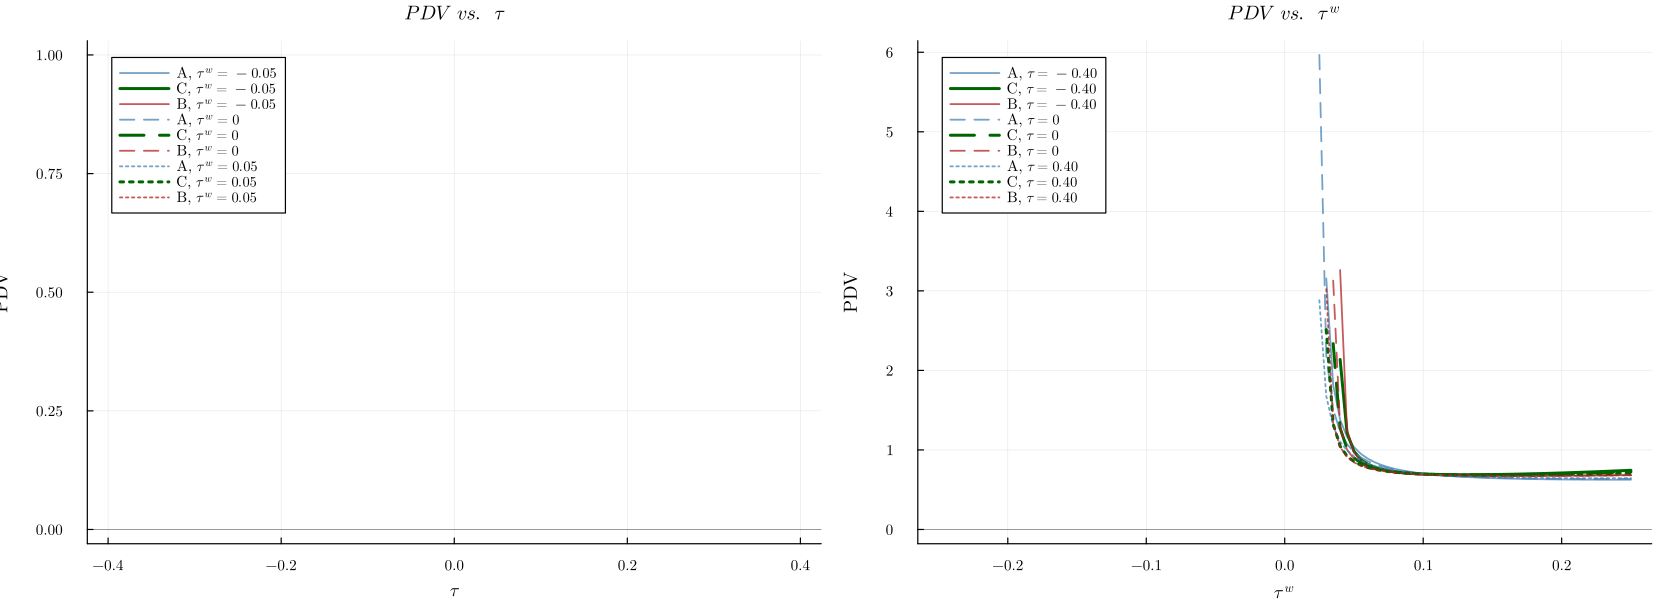

In [393]:
# ── Slice plots for PDV ──────────────────────────────────────────────────────

# Left: PDV vs τ at three values of τ_w
plot_left = plot(xlabel=L"\tau", ylabel="PDV",
                 title=L"PDV \;\ vs. \;\ \tau",
                 grid=true, legend=:topleft)
for (j, ls, label_w) in [(1,  :solid,  L"\tau^w=-0.05"),
                          (11, :dash,   L"\tau^w=0"),
                          (21, :dot,    L"\tau^w=0.05")]
    plot!(plot_left, τ_grid, PDV[:A][:, j]; label="A, " * label_w, color=:steelblue, linestyle=ls, linewidth=1.5, alpha=0.75)
    plot!(plot_left, τ_grid, PDV[:C][:, j]; label="C, " * label_w, color=:darkgreen, linestyle=ls, linewidth=2.5)
    plot!(plot_left, τ_grid, PDV[:B][:, j]; label="B, " * label_w, color=:firebrick, linestyle=ls, linewidth=1.5, alpha=0.75)
end
hline!(plot_left, [0]; color=:black, linewidth=0.5, alpha=0.6, label="")

# Right: PDV vs τ_w at three values of τ
plot_right = plot(xlabel=L"\tau^w", ylabel="PDV",
                  title=L"PDV \;\ vs. \;\ \tau^w",
                  grid=true, legend=:topleft)
for (i, ls, label_t) in [(1,  :solid, L"\tau=-0.40"),
                          (11, :dash,  L"\tau=0"),
                          (21, :dot,   L"\tau=0.40")]
    plot!(plot_right, τ_w_grid, PDV[:A][i, :]; label="A, " * label_t, color=:steelblue, linestyle=ls, linewidth=1.5, alpha=0.75)
    plot!(plot_right, τ_w_grid, PDV[:C][i, :]; label="C, " * label_t, color=:darkgreen, linestyle=ls, linewidth=2.5)
    plot!(plot_right, τ_w_grid, PDV[:B][i, :]; label="B, " * label_t, color=:firebrick, linestyle=ls, linewidth=1.5, alpha=0.75)
end
hline!(plot_right, [0]; color=:black, linewidth=0.5, alpha=0.6, label="")

plot(plot_left, plot_right; layout=(1,2), size=(1400, 500), margin=4Plots.mm)


In [394]:
# ── PDV-maximising tax pair — detailed breakdown ─────────────────────────────
function argmax_grid_pdv(M)
    idx = argmax(replace(M, NaN => -Inf))
    return idx[1], idx[2], M[idx]
end

@printf("β_gov = %.4f\n\n", β_gov)

for conv in [:A, :C, :B]
    i, j, pdv_max = argmax_grid_pdv(PDV[conv])
    label = conv == :C ? " (canonical)" : ""
    g_     = grids[conv][:g][i,j]
    T_     = grids[conv][:T][i,j]
    expg_  = exp(g_)
    bg_    = β_gov * expg_
    denom_ = 1 - bg_
    pdv_check = T_ / denom_

    @printf("Convention %s%s:\n", conv, label)
    @printf("  τ* = %+.3f,  τ_w* = %+.4f\n", τ_grid[i], τ_w_grid[j])
    @printf("  T/W        = %.6f\n", T_)
    @printf("  g (log)    = %+.6f  (%.2f%%)\n", g_, 100*g_)
    @printf("  exp(g)     = %.6f\n", expg_)
    @printf("  β_gov·G    = %.6f  (< 1? %s)\n", bg_, bg_ < 1 ? "✓" : "✗")
    @printf("  1 - β_gov·G= %.6f\n", denom_)
    @printf("  PDV = T / (1-βG) = %.6f / %.6f = %.6f\n", T_, denom_, pdv_check)
    @printf("  PDV (stored)     = %.6f\n", pdv_max)

    on_edge = (i == 1 || i == Nτ || j == 1 || j == Nτw)
    @printf("  Grid position: i=%d/%d, j=%d/%d  → %s\n\n",
            i, Nτ, j, Nτw, on_edge ? "BOUNDARY" : "INTERIOR")
end


β_gov = 0.9550

Convention A:
  τ* = -0.392,  τ_w* = +0.0250
  T/W        = 0.025000
  g (log)    = +0.045881  (4.59%)
  exp(g)     = 1.046950
  β_gov·G    = 0.999837  (< 1? ✓)
  1 - β_gov·G= 0.000163
  PDV = T / (1-βG) = 0.025000 / 0.000163 = 153.481250
  PDV (stored)     = 153.481250
  Grid position: i=2/101, j=56/101  → INTERIOR

Convention C (canonical):
  τ* = +0.256,  τ_w* = -0.0050
  T/W        = 0.011775
  g (log)    = +0.046027  (4.60%)
  exp(g)     = 1.047103
  β_gov·G    = 0.999983  (< 1? ✓)
  1 - β_gov·G= 0.000017
  PDV = T / (1-βG) = 0.011775 / 0.000017 = 699.272081
  PDV (stored)     = 699.272081
  Grid position: i=83/101, j=50/101  → INTERIOR

Convention B:
  τ* = +0.176,  τ_w* = +0.0000
  T/W        = 0.012487
  g (log)    = +0.045965  (4.60%)
  exp(g)     = 1.047038
  β_gov·G    = 0.999921  (< 1? ✓)
  1 - β_gov·G= 0.000079
  PDV = T / (1-βG) = 0.012487 / 0.000079 = 158.207823
  PDV (stored)     = 158.207823
  Grid position: i=73/101, j=51/101  → INTERIOR



## Discussion: Convention C is the Right One

Three observations from the simulation:

**1. The qualitative direction is robust.** With $\sigma_{CES} = 0.5$ (gross complements between $\tilde c$, $K^s$, $K^r$), both the wealth and the capital-income tax raise growth via the GE price channel in all three conventions: less savings demand → lower capital prices → higher returns → stronger savings incentive. This is the partial-equilibrium intuition (wealth tax is costly, income tax even more so via Domar–Musgrave) reversed by GE feedback. The reversal happens in A, C, and B alike.

**2. Quantitative magnitudes differ by a lot.** Convention A and Convention B sit at the extremes; Convention C — which we adopt as canonical — falls between them. The B/C wedge can be 2 percentage points at high taxes; the A/C wedge can be 10 percentage points. So any numerical claim about optimal taxation depends on the convention.

**3. Why C is the right one.** Convention C corresponds to the actual flow: income tax is paid out of *realized* end-of-period capital income, then spent in the *next* period. Conventions A and B are convenient simplifications — A treats the income tax as eternally sterilised (no current goods-market presence); B treats it as pre-collected against expected returns (an over-counting of current claims). Convention C respects the timing and, importantly, *uses no more state than $W$* once we impose stationarity:

$$\frac{G_t}{W_t} = \tau^w + \tau \cdot \mathbb{E}\!\left[\frac{r^p_{\text{before}}}{\bar R^p}\right].$$

The $(1-x^\ast)(1-\tau^w)$ factor that distinguishes B from C cancels precisely because in steady state $W_t/W_{t-1} = (1-x^\ast)(1-\tau^w)\bar R^p$. The "state of the economy" is $W_t$ — the agent's wealth — and the gov's lagged tax revenue is fully encoded in this state via the stationary growth identity.

**Implications for the homework.**

- **Question 8** (theoretical revenue-neutral comparison) is most naturally interpreted under Convention C. The revenue formula $T = \tau^w + \tau \mathbb{E}[r^p](1-x^\ast)(1-\tau^w)$ in the notes is from Convention B; the corresponding C-formula collapses to $\tau^w + \tau \mathbb{E}[r^p/\bar R^p]$. At low taxes these are numerically close, but at higher taxes they diverge.
- **Question 11** (GE feedback on the gross-up) holds in all three conventions but with different magnitudes. The qualitative argument (income-tax-induced portfolio rebalancing → $q^r$ up → $R^r$ down → equity premium compression) is robust.
- **Question 12** (computation) should commit to Convention C. The cells above provide the implementation; students who solve under A or B should expect their numbers to differ from C by the amounts shown in the difference plots.

**Sensitivity to $\sigma_{ces}$.** The GE channel strengthens as $\sigma$ falls (more complementarity). At $\sigma \to 1$ (Cobb–Douglas), value shares become invariant to prices and the channel weakens. At $\sigma > 1$ (gross substitutes), the channel can flip sign, magnifying the wealth-tax cost rather than offsetting it. This is the empirical handle in HW3 Question 7(c): the substitution elasticity between consumption and capital types is what distinguishes our model's predictions from those of frameworks like Guvenen et al. (2023) that emphasize ex-ante return heterogeneity.
